# 03 · Hypotheses and the evidence behind the model

**Question.** What will the test check, and what in the data shapes the model?

**Answer.**
- Four hypotheses, each with a stated failure condition (below).
- Silence is evidence: 67% of quotes end in a yes; 49% of those still quiet after 3 days; 23% after 7.
- Silence means less for customers who usually decline explicitly (repeat, referral) than for those
  who go quiet (marketplace). Significant in every type of work (p < 10⁻¹¹).

| | Claim | Test | Fails if |
|---|---|---|---|
| H1 | Ranking by chance today × amount wins more dollars than *newest first* or *biggest first* | Replay 1 Sep to 20 Dec 2024; dollars won by the first call vs the best possible pick | the 95% range of the gap includes zero |
| H2 | Quote details improve that ranking beyond days waiting | Same replay vs *days waiting × amount* | the range includes zero |
| H3 | The shown chance is right for each kind of quote | Predicted vs actual in 101 groups (work × source or speed × days waiting) | more groups miss than chance allows |
| H4 | Whether a lost customer declines or goes quiet depends on how they found the business | Chi-square within each type of work | p ≥ 0.01 in any type of work |

Ranges throughout are 95% intervals from 1,000 re-draws of whole businesses. H1 is the starting
question; H2 to H4 arose while building the model, which is why every modelling choice uses data from
before September only (notebook 04).

In [1]:
import sys

sys.path.insert(0, "../scripts")

import explore
import figures
import pandas as pd
import style
from IPython.display import Image, display

from quote_followup.config import load_settings
from quote_followup.data import load_quotes

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 100)
style.apply()
settings = load_settings("../config.toml")
quotes = load_quotes(settings.data_dir)

## 1. Sending speed

In [2]:
explore.speed_checks(quotes)

link between sending time and quote size, emergency job          0.009
link between sending time and quote size, one-off project       -0.016
link between sending time and quote size, recurring service     -0.003
effect of sending time, allowing for work and customer source   -0.161
  ... and also for quote size and number of items               -0.160
dtype: float64

In [3]:
explore.speed_by_size(quotes)

send_speed                  after a day  within a day
workflow_type     size                               
emergency job     smallest        0.821         0.850
                  small           0.780         0.815
                  large           0.761         0.830
                  largest         0.674         0.750
one-off project   smallest        0.500         0.750
                  small           0.450         0.562
                  large           0.533         0.571
                  largest         0.521         0.600
recurring service smallest        0.693         0.785
                  small           0.696         0.747
                  large           0.676         0.774

Faster quotes win in every type of work and size band, and the effect is unchanged by adjusting for size. An association, not proof of cause.

## 2. Silence

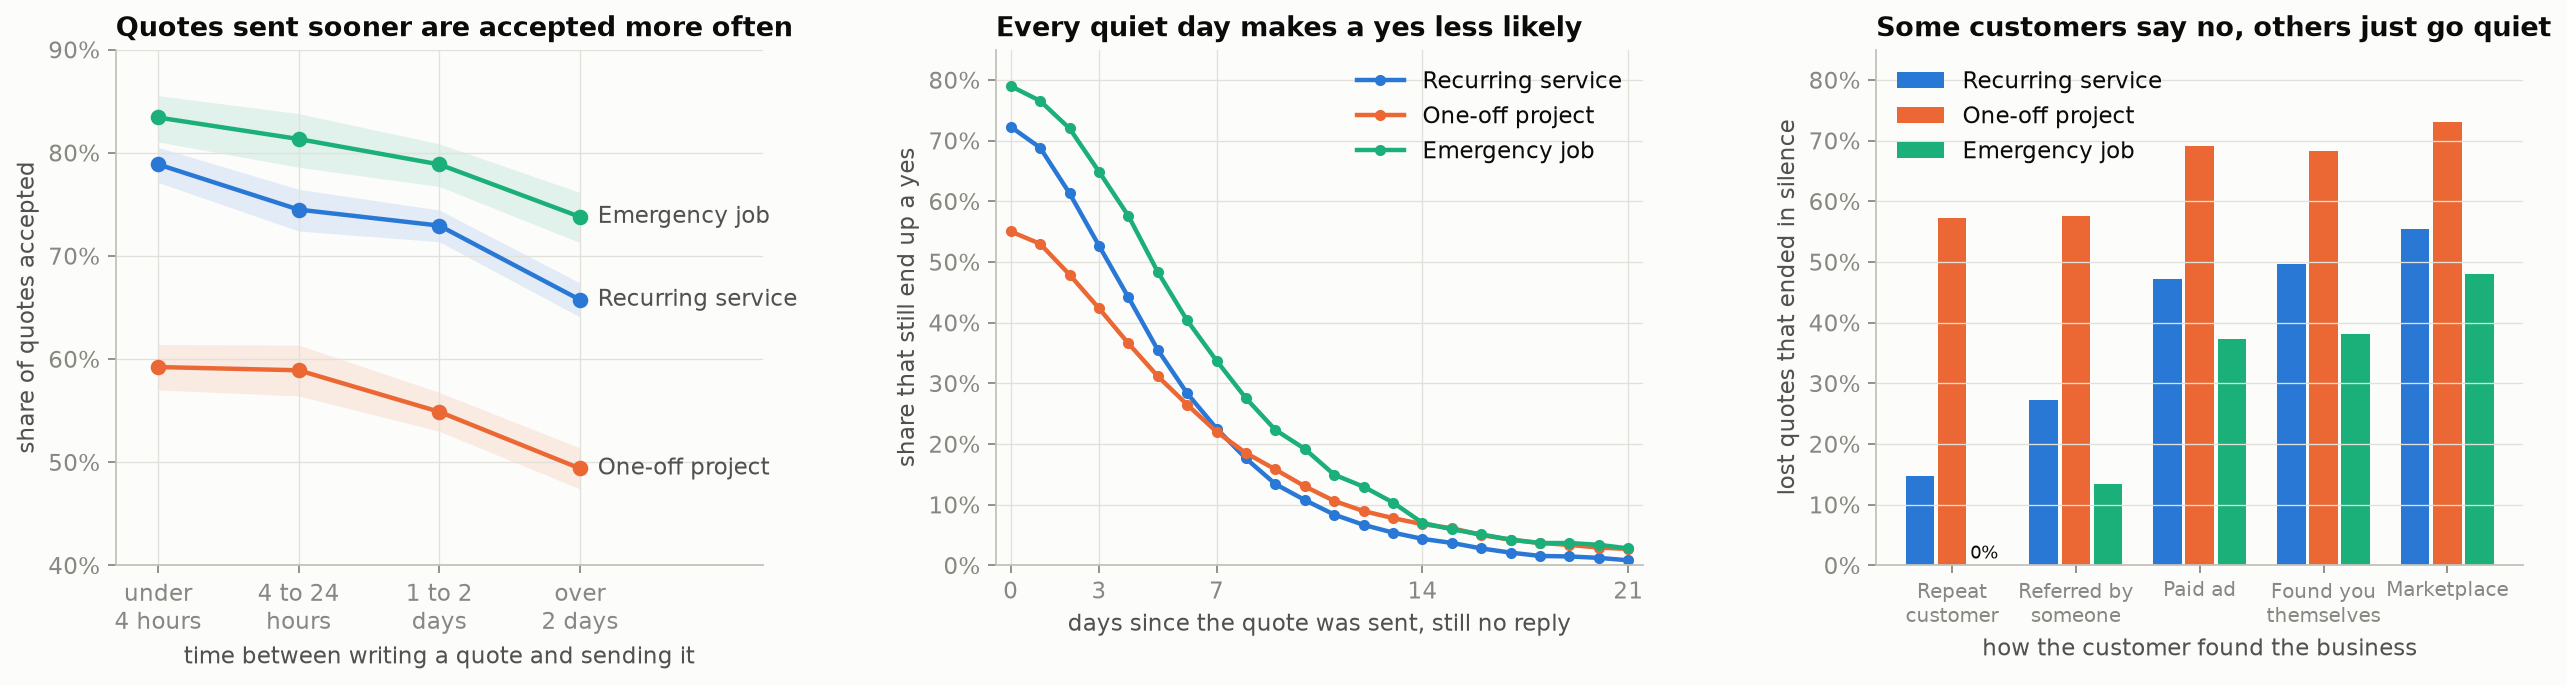

no reply after 0 days     0.673
no reply after 3 days     0.488
no reply after 7 days     0.232
no reply after 14 days    0.061
dtype: float64

In [4]:
figures.signals(quotes)
display(Image("../assets/signals.png"))
explore.still_quiet(quotes)

## 3. H4: declining vs going quiet

In [5]:
silent_share, luck = explore.loss_mix(quotes)
display(silent_share, luck)

workflow_type,emergency job,one-off project,recurring service
customer_channel,,,
came from a marketplace,0.479,0.730,0.554
found you on their own,0.381,0.682,0.497
came from a paid ad,0.372,0.691,0.471
referred by someone,0.134,0.576,0.272
repeat customer,0.000,0.573,0.148


emergency job        3.080473e-18
one-off project      2.413272e-12
recurring service    8.538558e-37
Name: chance this pattern is luck (p), dtype: float64

H4 holds in every type of work. A quiet repeat customer is less likely to be a loss than a quiet
marketplace lead, so the model must treat silence differently by customer.

## 4. The model

**Why a predictive model.** The decision is a ranking under a clear goal (dollars won), there are 23,556
past quotes with known endings to learn from, and the signals are structured fields known at sending. A
simple model is fast, cheap and explainable. LLMs and retrieval (RAG) have no text to read here; they
fit later work such as drafting the follow-up message. Clustering could later segment businesses and
customers.

**What it adds over rules of thumb:** a calibrated chance per quote that updates each day without a
reply, and reasons that add up exactly to its score.

Three parts, each learned from settled quotes:

1. *p*: chance of a yes at sending (logistic regression on type of work, customer source, log hours to send).
2. *q*: if lost, chance the customer declines rather than goes quiet (same inputs).
3. *S*: share of yeses and of nos still to come after *a* days, per type of work.

Each morning, Bayes' rule combines them:

$$\operatorname{logit} P(\text{yes} \mid \text{no reply after } a \text{ days}) = \operatorname{logit} p + \log S_\text{yes}(a) - \log\big[q\,S_\text{no}(a) + (1-q)\big]$$

This is a mixture model for competing outcomes (Larson and Dinse 1985).

## 5. Assumption check: reply speed by customer source (median days to a yes)

In [6]:
explore.days_to_yes(quotes)

workflow_type,emergency job,one-off project,recurring service
customer_channel,,,
came from a marketplace,1.25,2.33,1.29
found you on their own,1.29,2.33,1.29
came from a paid ad,1.25,3.04,1.29
referred by someone,1.33,3.08,1.29
repeat customer,1.25,3.04,1.25


Reply speed is flat across sources for recurring and emergency work, and varies by about a day for projects: the main limit of the model.